# LLM-13 · Lejebolig

Vi estimerer den annoncerede månedlige husleje i kroner ud fra lejlighedens areal i m². Den enkelte annonce er en observation.

Vi valgte de første ti annoncer på [BoligPortals liste over lejligheder i København](https://www.boligportal.dk/lejligheder/k%C3%B8benhavn/) ved opslag 23. november 2026. CSV-filen indeholder linket til hver annonce. Lejen er den annoncerede månedlige husleje. Særskilt aconto, depositum og forudbetalt husleje indgår ikke. Annoncer kan udløbe. Dette øvelsesdatasæt på ti annoncer beskriver et lille udsnit af markedet.

## 1. Læs data

`X` er input. `y` er værdien, vi vil forudsige.

In [1]:
import csv
from pathlib import Path

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

DATA_DIR = Path.cwd()

with (DATA_DIR / "dataset.csv").open(encoding="utf-8", newline="") as dataset:
    rows = list(csv.DictReader(dataset))

X = [[float(row["area_m2"])] for row in rows]
y = [float(row["monthly_rent_dkk"]) for row in rows]

## 2. Del data 80/20

Vi splitter `X` og `y` sammen, så værdier fra samme række følges ad. Vi bruger en fast seed, så delingen kan gentages.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Træning: {len(X_train)} rækker")
print(f"Test: {len(X_test)} rækker")

Træning: 8 rækker
Test: 2 rækker


## 3. Træn og test

Modellen lærer af `X_train` og `y_train`. Den forudsiger på `X_test`. `y_test` bruges til at måle afvigelsen. MAE er gennemsnittet af de absolutte fejl i samme enhed som målværdien.

In [3]:
model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

for (x,), actual, predicted in zip(X_test, y_test, predictions):
    print(f"X = {x:g} | Faktisk: {actual:,.2f} | Forudsagt: {predicted:,.2f}")

mae = mean_absolute_error(y_test, predictions)
print(f"MAE: {mae:,.2f}")

X = 85 | Faktisk: 14,500.00 | Forudsagt: 16,670.83
X = 117 | Faktisk: 20,486.00 | Forudsagt: 21,139.49
MAE: 1,412.16


In [5]:
from IPython.display import Markdown, display

def kroner(beløb):
    return f"{beløb:,.2f}".translate(str.maketrans(",.", ".,"))

rækker = [
    "| Boligareal | Faktisk husleje | Forudsagt husleje | Absolut fejl |",
    "|---:|---:|---:|---:|",
]

for (areal,), faktisk, forudsagt in zip(X_test, y_test, predictions):
    fejl = abs(faktisk - forudsagt)
    rækker.append(
        f"| {areal:g} m² | {kroner(faktisk)} kr. | "
        f"{kroner(forudsagt)} kr. | {kroner(fejl)} kr. |"
    )

rækker.append(f"| **MAE** | | | **{kroner(mae)} kr.** |")

display(Markdown("### Testresultater for månedlig husleje\n\n" + "\n".join(rækker)))

### Testresultater for månedlig husleje

| Boligareal | Faktisk husleje | Forudsagt husleje | Absolut fejl |
|---:|---:|---:|---:|
| 85 m² | 14.500,00 kr. | 16.670,83 kr. | 2.170,83 kr. |
| 117 m² | 20.486,00 kr. | 21.139,49 kr. | 653,49 kr. |
| **MAE** | | | **1.412,16 kr.** |

## 4. Se regressionslinjen

De stiplede stræk viser afstanden fra forudsigelse til den faktiske værdi.

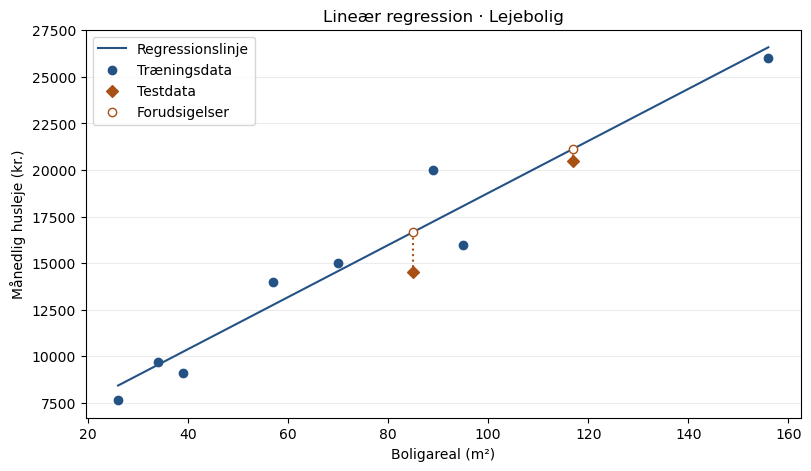

In [4]:
import matplotlib.pyplot as plt

train_values = [value for (value,) in X_train]
test_values = [value for (value,) in X_test]
line_values = [min(train_values), max(train_values)]
line_predictions = model.predict([[value] for value in line_values])

fig, ax = plt.subplots(figsize=(8, 4.6), layout="constrained")
ax.plot(line_values, line_predictions, color="#245285", label="Regressionslinje")
ax.scatter(train_values, y_train, color="#245285", zorder=3, label="Træningsdata")
ax.scatter(test_values, y_test, color="#a95015", marker="D", zorder=3, label="Testdata")
ax.scatter(test_values, predictions, facecolors="white", edgecolors="#a95015",
           zorder=3, label="Forudsigelser")
ax.vlines(test_values, predictions, y_test, colors="#a95015", linestyles="dotted")
ax.set(title="Lineær regression · Lejebolig", xlabel='Boligareal (m²)', ylabel='Månedlig husleje (kr.)')
ax.grid(axis="y", alpha=0.24)
ax.legend()
plt.show()